In [10]:
#Empty_records

In [11]:
import pandas as pd

In [12]:

df = pd.read_csv("housing.csv")



In [13]:
print("Total empty values:", df.isna().sum().sum())

Total empty values: 207


In [14]:
print(df.isna().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [15]:
import numpy as np
import pandas as pd

In [16]:
# Make sure we're working with a copy
test_df = df.copy()

In [17]:
# Find rows where total_bedrooms is NOT missing
known_rows = test_df[test_df["total_bedrooms"].notna()].index

In [18]:
# Randomly select 207 known rows to simulate missing values
np.random.seed(42)
hidden_rows = np.random.choice(known_rows, size=207, replace=False)

In [19]:
# Randomly select 207 known rows to simulate missing values
np.random.seed(42)
hidden_rows = np.random.choice(known_rows, size=207, replace=False)

In [20]:
actual_bedrooms = test_df.loc[hidden_rows, "total_bedrooms"].copy()


In [21]:
test_df.loc[hidden_rows, "total_bedrooms"] = np.nan


In [22]:
print("Number of artificially hidden values:", test_df.loc[hidden_rows, "total_bedrooms"].isna().sum())


Number of artificially hidden values: 207


In [23]:
print("Number of actual values saved for comparison:", len(actual_bedrooms))

Number of actual values saved for comparison: 207


In [24]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [25]:
features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

In [26]:
# Scale the numerical features so large-valued columns don't dominate KNN
scaler = StandardScaler()
scaled_data = scaler.fit_transform(test_df[features])

In [27]:
# KNN imputation
knn_imputer = KNNImputer(
    n_neighbors=5,
    weights="distance"
)

In [28]:
imputed_scaled = knn_imputer.fit_transform(scaled_data)

In [29]:
imputed_data = scaler.inverse_transform(imputed_scaled)

In [30]:
knn_df = pd.DataFrame(
    imputed_data,
    columns=features,
    index=test_df.index
)

In [31]:
knn_predictions = knn_df.loc[hidden_rows, "total_bedrooms"]

In [32]:
print("KNN imputation completed.")

KNN imputation completed.


In [33]:
print("Predictions available:", len(knn_predictions))

Predictions available: 207


In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


In [35]:
knn_mae = mean_absolute_error(
    actual_bedrooms,
    knn_predictions
)

In [36]:
knn_rmse = np.sqrt(
    mean_squared_error(
        actual_bedrooms,
        knn_predictions
    )
)


In [37]:
print("Total predictions:", len(knn_predictions))

Total predictions: 207


In [38]:
print("Missing predictions:", knn_predictions.isna().sum())

Missing predictions: 0


In [39]:
print("Actual dtype:", actual_bedrooms.dtype)


Actual dtype: float64


In [40]:
print("KNN dtype:", knn_predictions.dtype)


KNN dtype: float64


In [41]:
print("Actual NaN:", np.isnan(actual_bedrooms).sum())


Actual NaN: 0


In [42]:
print("KNN NaN:", np.isnan(knn_predictions).sum())


KNN NaN: 0


In [43]:
print("Actual infinite:", np.isinf(actual_bedrooms).sum())


Actual infinite: 0


In [44]:
print("KNN infinite:", np.isinf(knn_predictions).sum())

KNN infinite: 0


In [45]:
# Recreate the experiment from the original dataset

test_df = df.copy()

# Find rows where total_bedrooms is originally known
known_rows = test_df[test_df["total_bedrooms"].notna()].index

# Select the same 207 rows
np.random.seed(42)
hidden_rows = np.random.choice(known_rows, size=207, replace=False)

# IMPORTANT: save original values from df BEFORE hiding anything
actual_bedrooms = df.loc[hidden_rows, "total_bedrooms"].copy()

# Now hide those values
test_df.loc[hidden_rows, "total_bedrooms"] = np.nan

print("Actual NaN:", actual_bedrooms.isna().sum())
print("Artificially hidden:", test_df.loc[hidden_rows, "total_bedrooms"].isna().sum())

Actual NaN: 0
Artificially hidden: 207


In [46]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

# Scale the features
scaler = StandardScaler()
scaled_data = scaler.fit_transform(test_df[features])

# KNN imputation
knn_imputer = KNNImputer(
    n_neighbors=5,
    weights="distance"
)

imputed_scaled = knn_imputer.fit_transform(scaled_data)

# Convert back to original scale
imputed_data = scaler.inverse_transform(imputed_scaled)

# Create DataFrame
knn_df = pd.DataFrame(
    imputed_data,
    columns=features,
    index=test_df.index
)

# Extract predictions for ONLY our 207 hidden values
knn_predictions = knn_df.loc[hidden_rows, "total_bedrooms"]

print("Predictions available:", len(knn_predictions))
print("Missing predictions:", knn_predictions.isna().sum())

Predictions available: 207
Missing predictions: 0


In [47]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

knn_mae = mean_absolute_error(
    actual_bedrooms,
    knn_predictions
)

knn_rmse = np.sqrt(
    mean_squared_error(
        actual_bedrooms,
        knn_predictions
    )
)

print("KNN MAE:", knn_mae)
print("KNN RMSE:", knn_rmse)

KNN MAE: 41.75614692371296
KNN RMSE: 71.43328206380225


In [48]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import StandardScaler

# Scale the same features used for KNN
scaler_iter = StandardScaler()
scaled_data_iter = scaler_iter.fit_transform(test_df[features])

# Iterative imputation
iter_imputer = IterativeImputer(
    estimator=BayesianRidge(),
    max_iter=10,
    random_state=42
)

iter_imputed_scaled = iter_imputer.fit_transform(scaled_data_iter)

# Convert back to original scale
iter_imputed_data = scaler_iter.inverse_transform(iter_imputed_scaled)

# Create DataFrame
iter_df = pd.DataFrame(
    iter_imputed_data,
    columns=features,
    index=test_df.index
)

# Extract predictions for the SAME 207 hidden rows
iter_predictions = iter_df.loc[hidden_rows, "total_bedrooms"]

print("Predictions available:", len(iter_predictions))
print("Missing predictions:", iter_predictions.isna().sum())

Predictions available: 207
Missing predictions: 0


In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

iter_mae = mean_absolute_error(
    actual_bedrooms,
    iter_predictions
)

iter_rmse = np.sqrt(
    mean_squared_error(
        actual_bedrooms,
        iter_predictions
    )
)

print("Iterative MAE:", iter_mae)
print("Iterative RMSE:", iter_rmse)

Iterative MAE: 41.714047114859554
Iterative RMSE: 92.52092755025397


In [50]:
comparison = pd.DataFrame({
    "Actual": actual_bedrooms,
    "KNN": knn_predictions,
    "Iterative": iter_predictions
})

comparison["KNN_Error"] = abs(
    comparison["Actual"] - comparison["KNN"]
)

comparison["Iterative_Error"] = abs(
    comparison["Actual"] - comparison["Iterative"]
)

comparison["Error_Difference"] = (
    comparison["Iterative_Error"] - comparison["KNN_Error"]
)

comparison.sort_values(
    "Iterative_Error",
    ascending=False
).head(10)

,Actual,KNN,Iterative,KNN_Error,Iterative_Error,Error_Difference
12375,3479.0,2936.159572,2486.077995,542.840428,992.922005,450.081577
13924,1283.0,1341.059730,771.903952,58.059730,511.096048,453.036318
12002,1491.0,1580.860832,1697.858559,89.860832,206.858559,116.997728
5923,1161.0,1281.356678,1360.754719,120.356678,199.754719,79.398041
13099,2282.0,2399.601895,2443.203471,117.601895,161.203471,43.601577
11707,372.0,331.069089,212.727894,40.930911,159.272106,118.341195
4672,1252.0,1230.039344,1096.272915,21.960656,155.727085,133.766429
3645,1168.0,1189.545809,1020.258523,21.545809,147.741477,126.195668
9418,29.0,93.691056,-112.377661,64.691056,141.377661,76.686605
15532,974.0,1081.511288,1102.521561,107.511288,128.521561,21.010274


In [51]:
print("Negative Iterative predictions:",
      (iter_predictions < 0).sum())

print("Negative KNN predictions:",
      (knn_predictions < 0).sum())

Negative Iterative predictions: 2
Negative KNN predictions: 0


In [52]:
print("Actual hidden values:")
print(actual_bedrooms.describe())

print("\nKNN predicted values:")
print(knn_predictions.describe())

print("\nIterative predicted values:")
print(iter_predictions.describe())


Actual hidden values:
count     207.000000
mean      617.835749
std       524.285146
min        18.000000
25%       302.000000
50%       441.000000
75%       670.500000
max      3479.000000
Name: total_bedrooms, dtype: float64

KNN predicted values:
count     207.000000
mean      602.898118
std       490.966855
min        45.713415
25%       309.512104
50%       424.770411
75%       683.949576
max      2936.159572
Name: total_bedrooms, dtype: float64

Iterative predicted values:
count     207.000000
mean      609.809816
std       506.455399
min      -112.377661
25%       303.407002
50%       443.444713
75%       682.425749
max      2945.672963
Name: total_bedrooms, dtype: float64


In [53]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# Work on a copy — keep the original df untouched
df_knn = df.copy()

features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

# Scale the numerical features
scaler_final = StandardScaler()
scaled_data = scaler_final.fit_transform(df_knn[features])

# KNN imputer
knn_final = KNNImputer(
    n_neighbors=5,
    weights="distance"
)

# Impute
imputed_scaled = knn_final.fit_transform(scaled_data)

# Convert back to original units
imputed_data = scaler_final.inverse_transform(imputed_scaled)

# Put the imputed values back into the dataframe
imputed_df = pd.DataFrame(
    imputed_data,
    columns=features,
    index=df_knn.index
)

df_knn["total_bedrooms"] = imputed_df["total_bedrooms"]

print("Missing values before:", df["total_bedrooms"].isna().sum())
print("Missing values after:", df_knn["total_bedrooms"].isna().sum())

Missing values before: 207
Missing values after: 0


In [54]:
# Find the rows that originally had missing total_bedrooms
missing_rows = df[df["total_bedrooms"].isna()].index

# Compare original vs imputed values
imputed_check = pd.DataFrame({
    "Original": df.loc[missing_rows, "total_bedrooms"],
    "KNN_Imputed": df_knn.loc[missing_rows, "total_bedrooms"]
})

print(imputed_check.head(10))
print("\nNumber of imputed rows:", len(imputed_check))
print("Missing after imputation:", imputed_check["KNN_Imputed"].isna().sum())

      Original  KNN_Imputed
290        NaN   255.856793
341        NaN   254.741995
538        NaN  1302.100524
563        NaN   189.210805
696        NaN   149.944606
738        NaN   565.033162
1097       NaN   624.059379
1350       NaN  1092.076209
1456       NaN   547.979668
1493       NaN   467.883266

Number of imputed rows: 207
Missing after imputation: 0


In [55]:
print("Shape:", df_knn.shape)

print("\nData types:")
print(df_knn.dtypes)

print("\nMissing values:")
print(df_knn.isna().sum())

print("\nDuplicate rows:", df_knn.duplicated().sum())

Shape: (20640, 10)

Data types:
longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity        object
dtype: object

Missing values:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

Duplicate rows: 0


In [56]:
pd.set_option("display.float_format", "{:.2f}".format)

df_knn.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.85,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.02,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


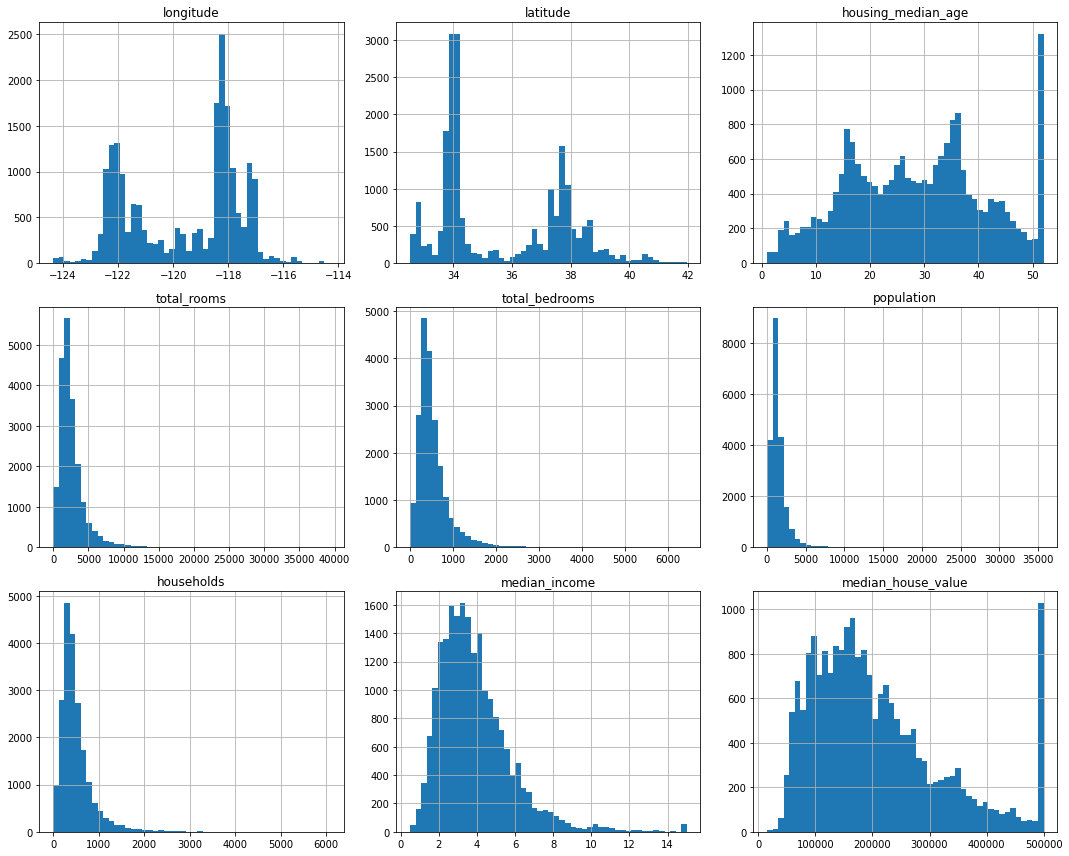

In [57]:
import matplotlib.pyplot as plt

df_knn.hist(
    figsize=(15, 12),
    bins=50
)

plt.tight_layout()
plt.show()

In [58]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

for alpha in np.arange(0, 1.01, 0.1):

    # Hybrid prediction
    hybrid = (
        alpha * knn_predictions
        + (1 - alpha) * iter_predictions
    )

    # Bedrooms cannot be negative
    hybrid = np.maximum(hybrid, 0)

    # Metrics
    mae = mean_absolute_error(
        actual_bedrooms,
        hybrid
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_bedrooms,
            hybrid
        )
    )

    results.append({
        "KNN_Weight": alpha,
        "Iterative_Weight": 1 - alpha,
        "MAE": mae,
        "RMSE": rmse,
        "Negative_Predictions": (hybrid < 0).sum()
    })

hybrid_results = pd.DataFrame(results)

print(hybrid_results)

    KNN_Weight  Iterative_Weight   MAE  RMSE  Negative_Predictions
0         0.00              1.00 40.82 91.73                     0
1         0.10              0.90 38.61 86.66                     0
2         0.20              0.80 37.41 82.05                     0
3         0.30              0.70 36.51 77.99                     0
4         0.40              0.60 35.96 74.56                     0
5         0.50              0.50 35.77 71.86                     0
6         0.60              0.40 35.95 69.95                     0
7         0.70              0.30 36.67 68.89                     0
8         0.80              0.20 37.86 68.79                     0
9         0.90              0.10 39.39 69.65                     0
10        1.00              0.00 41.76 71.43                     0


In [59]:
fine_results = []

for alpha in np.arange(0.50, 0.91, 0.01):

    hybrid = (
        alpha * knn_predictions
        + (1 - alpha) * iter_predictions
    )

    # Enforce non-negative bedroom counts
    hybrid = np.maximum(hybrid, 0)

    mae = mean_absolute_error(
        actual_bedrooms,
        hybrid
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_bedrooms,
            hybrid
        )
    )

    fine_results.append({
        "KNN_Weight": alpha,
        "Iterative_Weight": 1 - alpha,
        "MAE": mae,
        "RMSE": rmse
    })

fine_results = pd.DataFrame(fine_results)

print("Best MAE:")
print(
    fine_results.loc[
        fine_results["MAE"].idxmin()
    ]
)

print("\nBest RMSE:")
print(
    fine_results.loc[
        fine_results["RMSE"].idxmin()
    ]
)

Best MAE:
KNN_Weight          0.50
Iterative_Weight    0.50
MAE                35.77
RMSE               71.86
Name: 0, dtype: float64

Best RMSE:
KNN_Weight          0.76
Iterative_Weight    0.24
MAE                37.33
RMSE               68.72
Name: 26, dtype: float64


In [60]:
# Split our 207 validation cases into calibration and holdout sets

np.random.seed(42)

validation_indices = np.arange(len(hidden_rows))
np.random.shuffle(validation_indices)

calibration_indices = validation_indices[:104]
holdout_indices = validation_indices[104:]

print("Calibration cases:", len(calibration_indices))
print("Holdout cases:", len(holdout_indices))

Calibration cases: 104
Holdout cases: 103


In [61]:
# Find the best hybrid weight using ONLY the calibration set

cal_actual = actual_bedrooms.iloc[calibration_indices]
cal_knn = knn_predictions.iloc[calibration_indices]
cal_iter = iter_predictions.iloc[calibration_indices]

calibration_results = []

for alpha in np.arange(0, 1.001, 0.01):

    hybrid = (
        alpha * cal_knn
        + (1 - alpha) * cal_iter
    )

    # total_bedrooms cannot be negative
    hybrid = np.maximum(hybrid, 0)

    mae = mean_absolute_error(cal_actual, hybrid)

    rmse = np.sqrt(
        mean_squared_error(cal_actual, hybrid)
    )

    calibration_results.append({
        "KNN_Weight": alpha,
        "Iterative_Weight": 1 - alpha,
        "MAE": mae,
        "RMSE": rmse
    })

calibration_results = pd.DataFrame(calibration_results)

best_cal_mae = calibration_results.loc[
    calibration_results["MAE"].idxmin()
]

best_cal_rmse = calibration_results.loc[
    calibration_results["RMSE"].idxmin()
]

print("BEST CALIBRATION WEIGHT — MAE")
print(best_cal_mae)

print("\nBEST CALIBRATION WEIGHT — RMSE")
print(best_cal_rmse)

BEST CALIBRATION WEIGHT — MAE
KNN_Weight          0.31
Iterative_Weight    0.69
MAE                36.47
RMSE               92.84
Name: 31, dtype: float64

BEST CALIBRATION WEIGHT — RMSE
KNN_Weight          0.86
Iterative_Weight    0.14
MAE                41.31
RMSE               82.45
Name: 86, dtype: float64


In [62]:
# Evaluate the calibration-selected weights on the untouched holdout set

hold_actual = actual_bedrooms.iloc[holdout_indices]
hold_knn = knn_predictions.iloc[holdout_indices]
hold_iter = iter_predictions.iloc[holdout_indices]

# Baseline: KNN
knn_mae = mean_absolute_error(hold_actual, hold_knn)
knn_rmse = np.sqrt(
    mean_squared_error(hold_actual, hold_knn)
)

# Baseline: Iterative
iter_pred = np.maximum(hold_iter, 0)

iter_mae = mean_absolute_error(hold_actual, iter_pred)
iter_rmse = np.sqrt(
    mean_squared_error(hold_actual, iter_pred)
)

# Hybrid chosen by calibration MAE
alpha_mae = best_cal_mae["KNN_Weight"]

hybrid_mae_pred = (
    alpha_mae * hold_knn
    + (1 - alpha_mae) * hold_iter
)

hybrid_mae_pred = np.maximum(hybrid_mae_pred, 0)

hybrid_mae = mean_absolute_error(
    hold_actual,
    hybrid_mae_pred
)

hybrid_mae_rmse = np.sqrt(
    mean_squared_error(
        hold_actual,
        hybrid_mae_pred
    )
)

# Hybrid chosen by calibration RMSE
alpha_rmse = best_cal_rmse["KNN_Weight"]

hybrid_rmse_pred = (
    alpha_rmse * hold_knn
    + (1 - alpha_rmse) * hold_iter
)

hybrid_rmse_pred = np.maximum(hybrid_rmse_pred, 0)

hybrid_rmse_mae = mean_absolute_error(
    hold_actual,
    hybrid_rmse_pred
)

hybrid_rmse = np.sqrt(
    mean_squared_error(
        hold_actual,
        hybrid_rmse_pred
    )
)

# Comparison
holdout_results = pd.DataFrame({
    "Method": [
        "KNN",
        "Iterative",
        "Hybrid (MAE tuned)",
        "Hybrid (RMSE tuned)"
    ],
    "MAE": [
        knn_mae,
        iter_mae,
        hybrid_mae,
        hybrid_rmse_mae
    ],
    "RMSE": [
        knn_rmse,
        iter_rmse,
        hybrid_mae_rmse,
        hybrid_rmse
    ]
})

print(holdout_results)

                Method   MAE  RMSE
0                  KNN 39.24 57.16
1            Iterative 42.59 74.50
2   Hybrid (MAE tuned) 36.38 58.34
3  Hybrid (RMSE tuned) 36.10 52.52


In [63]:
# Repeated calibration + holdout stability check

from sklearn.metrics import mean_absolute_error, mean_squared_error

seeds = [7, 21, 42, 84, 123]

stability_results = []

for seed in seeds:

    rng = np.random.default_rng(seed)

    indices = np.arange(len(hidden_rows))
    rng.shuffle(indices)

    split_point = len(indices) // 2

    cal_idx = indices[:split_point]
    hold_idx = indices[split_point:]

    # Calibration data
    cal_actual = actual_bedrooms.iloc[cal_idx]
    cal_knn = knn_predictions.iloc[cal_idx]
    cal_iter = iter_predictions.iloc[cal_idx]

    # Tune alpha using calibration only
    best_alpha = None
    best_rmse = np.inf

    for alpha in np.arange(0, 1.001, 0.01):

        pred = (
            alpha * cal_knn
            + (1 - alpha) * cal_iter
        )

        pred = np.maximum(pred, 0)

        rmse = np.sqrt(
            mean_squared_error(cal_actual, pred)
        )

        if rmse < best_rmse:
            best_rmse = rmse
            best_alpha = alpha

    # Fresh holdout
    hold_actual = actual_bedrooms.iloc[hold_idx]
    hold_knn = knn_predictions.iloc[hold_idx]
    hold_iter = iter_predictions.iloc[hold_idx]

    # Hybrid
    hybrid = (
        best_alpha * hold_knn
        + (1 - best_alpha) * hold_iter
    )

    hybrid = np.maximum(hybrid, 0)

    # Metrics
    knn_mae = mean_absolute_error(
        hold_actual,
        hold_knn
    )

    knn_rmse = np.sqrt(
        mean_squared_error(
            hold_actual,
            hold_knn
        )
    )

    hybrid_mae = mean_absolute_error(
        hold_actual,
        hybrid
    )

    hybrid_rmse = np.sqrt(
        mean_squared_error(
            hold_actual,
            hybrid
        )
    )

    stability_results.append({
        "Seed": seed,
        "KNN_Weight": best_alpha,
        "Iterative_Weight": 1 - best_alpha,
        "KNN_MAE": knn_mae,
        "Hybrid_MAE": hybrid_mae,
        "KNN_RMSE": knn_rmse,
        "Hybrid_RMSE": hybrid_rmse
    })

stability_results = pd.DataFrame(stability_results)

print(stability_results)

   Seed  KNN_Weight  Iterative_Weight  KNN_MAE  Hybrid_MAE  KNN_RMSE  \
0     7        0.96              0.04    42.44       41.39     64.77   
1    21        1.00              0.00    43.71       43.71     70.53   
2    42        0.91              0.09    39.45       37.70     59.98   
3    84        0.40              0.60    48.61       43.63     84.12   
4   123        0.57              0.43    40.85       37.55     80.21   

   Hybrid_RMSE  
0        63.08  
1        70.53  
2        56.61  
3        97.00  
4        86.34  


In [64]:
# Aggregate performance across repeated validation splits

summary = pd.DataFrame({
    "Metric": [
        "Average MAE",
        "Average RMSE",
        "MAE Std",
        "RMSE Std"
    ],
    "KNN": [
        stability_results["KNN_MAE"].mean(),
        stability_results["KNN_RMSE"].mean(),
        stability_results["KNN_MAE"].std(),
        stability_results["KNN_RMSE"].std()
    ],
    "Hybrid": [
        stability_results["Hybrid_MAE"].mean(),
        stability_results["Hybrid_RMSE"].mean(),
        stability_results["Hybrid_MAE"].std(),
        stability_results["Hybrid_RMSE"].std()
    ]
})

print(summary)

print("\nAverage improvement:")
print(
    "MAE:",
    stability_results["KNN_MAE"].mean()
    - stability_results["Hybrid_MAE"].mean()
)

print(
    "RMSE:",
    stability_results["KNN_RMSE"].mean()
    - stability_results["Hybrid_RMSE"].mean()
)

print("\nNumber of splits where Hybrid beats KNN:")
print(
    "MAE:",
    (stability_results["Hybrid_MAE"]
     < stability_results["KNN_MAE"]).sum(),
    "/",
    len(stability_results)
)

print(
    "RMSE:",
    (stability_results["Hybrid_RMSE"]
     < stability_results["KNN_RMSE"]).sum(),
    "/",
    len(stability_results)
)

         Metric   KNN  Hybrid
0   Average MAE 43.01   40.79
1  Average RMSE 71.92   74.71
2       MAE Std  3.52    3.04
3      RMSE Std 10.16   16.68

Average improvement:
MAE: 2.2163130725982327
RMSE: -2.789567292056276

Number of splits where Hybrid beats KNN:
MAE: 4 / 5
RMSE: 2 / 5


In [65]:
# Final validation of the selected KNN-imputed dataset

missing_before = df["total_bedrooms"].isna().sum()
missing_after = df_knn["total_bedrooms"].isna().sum()

negative_values = (
    df_knn["total_bedrooms"] < 0
).sum()

print("Original missing values:", missing_before)
print("Missing after KNN:", missing_after)
print("Negative imputed values:", negative_values)
print("Final shape:", df_knn.shape)

print("\nOriginal missing rows:")
print(missing_rows[:10].tolist())

print("\nFinal imputed values:")
print(
    df_knn.loc[
        missing_rows,
        "total_bedrooms"
    ].head(10)
)

Original missing values: 207
Missing after KNN: 0
Negative imputed values: 0
Final shape: (20640, 10)

Original missing rows:
[290, 341, 538, 563, 696, 738, 1097, 1350, 1456, 1493]

Final imputed values:
290     255.86
341     254.74
538    1302.10
563     189.21
696     149.94
738     565.03
1097    624.06
1350   1092.08
1456    547.98
1493    467.88
Name: total_bedrooms, dtype: float64


In [66]:
# Step 1: Detect potential outliers using IQR

numeric_columns = [
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
    "median_house_value"
]

outlier_summary = []

for col in numeric_columns:

    Q1 = df_knn[col].quantile(0.25)
    Q3 = df_knn[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df_knn[col] < lower_bound) |
        (df_knn[col] > upper_bound)
    )

    outlier_summary.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outliers.sum(),
        "Outlier_Percentage": outliers.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary)

print(outlier_summary)

              Feature        Q1        Q3       IQR  Lower_Bound  Upper_Bound  \
0  housing_median_age     18.00     37.00     19.00       -10.50        65.50   
1         total_rooms   1447.75   3148.00   1700.25     -1102.62      5698.38   
2      total_bedrooms    296.00    647.00    351.00      -230.50      1173.50   
3          population    787.00   1725.00    938.00      -620.00      3132.00   
4          households    280.00    605.00    325.00      -207.50      1092.50   
5       median_income      2.56      4.74      2.18        -0.71         8.01   
6  median_house_value 119600.00 264725.00 145125.00    -98087.50    482412.50   

   Outlier_Count  Outlier_Percentage  
0              0                0.00  
1           1287                6.24  
2           1286                6.23  
3           1196                5.79  
4           1220                5.91  
5            681                3.30  
6           1071                5.19  


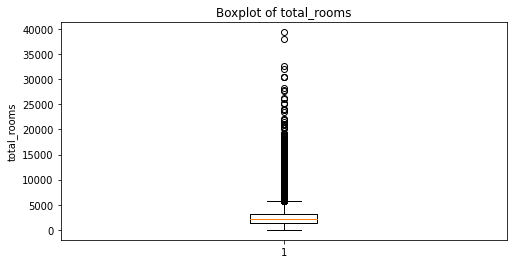

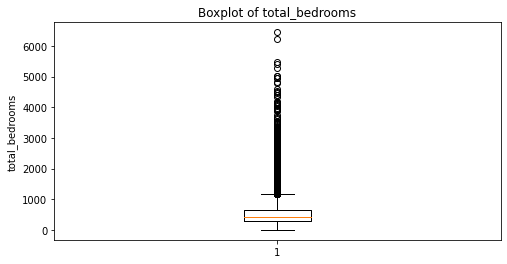

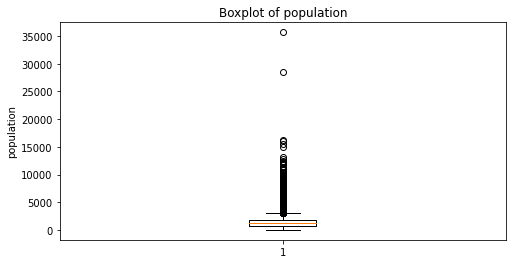

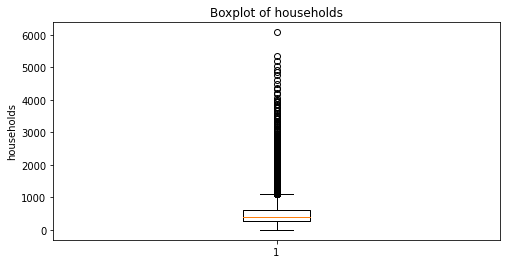

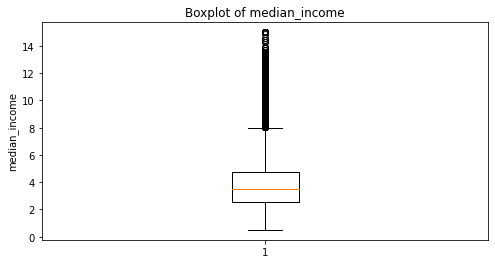

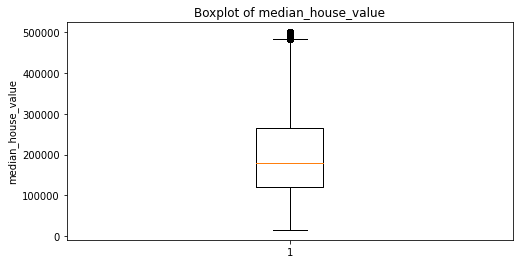

In [67]:
import matplotlib.pyplot as plt

outlier_features = [
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
    "median_house_value"
]

for col in outlier_features:

    plt.figure(figsize=(8, 4))

    plt.boxplot(df_knn[col])

    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)

    plt.show()

In [68]:
# Check relationships between the extreme-count variables

ratio_df = pd.DataFrame({
    "rooms_per_bedroom": (
        df_knn["total_rooms"] /
        df_knn["total_bedrooms"]
    ),
    
    "people_per_household": (
        df_knn["population"] /
        df_knn["households"]
    ),
    
    "rooms_per_household": (
        df_knn["total_rooms"] /
        df_knn["households"]
    )
})

print("Rooms per bedroom:")
print(ratio_df["rooms_per_bedroom"].describe())

print("\nPeople per household:")
print(ratio_df["people_per_household"].describe())

print("\nRooms per household:")
print(ratio_df["rooms_per_household"].describe())

Rooms per bedroom:
count   20640.00
mean        4.98
std         1.17
min         1.00
25%         4.17
50%         4.92
75%         5.70
max        10.00
Name: rooms_per_bedroom, dtype: float64

People per household:
count   20640.00
mean        3.07
std        10.39
min         0.69
25%         2.43
50%         2.82
75%         3.28
max      1243.33
Name: people_per_household, dtype: float64

Rooms per household:
count   20640.00
mean        5.43
std         2.47
min         0.85
25%         4.44
50%         5.23
75%         6.05
max       141.91
Name: rooms_per_household, dtype: float64


In [69]:
# Inspect the most extreme ratio cases

ratio_check = df_knn.copy()

ratio_check["people_per_household"] = (
    ratio_check["population"] /
    ratio_check["households"]
)

ratio_check["rooms_per_household"] = (
    ratio_check["total_rooms"] /
    ratio_check["households"]
)

print("Top 10 people_per_household cases:")
print(
    ratio_check[
        [
            "population",
            "households",
            "total_rooms",
            "total_bedrooms",
            "people_per_household"
        ]
    ]
    .sort_values("people_per_household", ascending=False)
    .head(10)
)

print("\nTop 10 rooms_per_household cases:")
print(
    ratio_check[
        [
            "total_rooms",
            "total_bedrooms",
            "population",
            "households",
            "rooms_per_household"
        ]
    ]
    .sort_values("rooms_per_household", ascending=False)
    .head(10)
)

Top 10 people_per_household cases:
       population  households  total_rooms  total_bedrooms  \
19006     7460.00        6.00        19.00            5.00   
3364      4198.00        7.00        36.00            8.00   
16669     6532.00       13.00       118.00           17.00   
13034     6675.00       29.00       240.00           44.00   
9172      8733.00      105.00       538.00           98.00   
12104     1275.00       20.00       152.00           19.00   
16420     1542.00       30.00       161.00           27.00   
8874      1154.00       28.00       204.00           34.00   
13366     2886.00       85.00       447.00           95.00   
5986      2688.00      126.00       567.00          152.00   

       people_per_household  
19006               1243.33  
3364                 599.71  
16669                502.46  
13034                230.17  
9172                  83.17  
12104                 63.75  
16420                 51.40  
8874                  41.21  
13366       

In [70]:
# Quantify potentially problematic ratio observations

people_ratio = (
    df_knn["population"] /
    df_knn["households"]
)

rooms_ratio = (
    df_knn["total_rooms"] /
    df_knn["households"]
)

# Thresholds chosen for investigation, NOT automatic deletion
people_extreme = people_ratio > 10
rooms_extreme = rooms_ratio > 20

print("People per household > 10:")
print("Count:", people_extreme.sum())
print("Percentage:", people_extreme.mean() * 100)

print("\nRooms per household > 20:")
print("Count:", rooms_extreme.sum())
print("Percentage:", rooms_extreme.mean() * 100)

print("\nBoth conditions:")
both_extreme = people_extreme & rooms_extreme
print("Count:", both_extreme.sum())
print("Percentage:", both_extreme.mean() * 100)

People per household > 10:
Count: 37
Percentage: 0.17926356589147285

Rooms per household > 20:
Count: 69
Percentage: 0.33430232558139533

Both conditions:
Count: 1
Percentage: 0.0048449612403100775


In [71]:
# Inspect the potentially problematic observations

investigation = df_knn.copy()

investigation["people_per_household"] = (
    investigation["population"] /
    investigation["households"]
)

investigation["rooms_per_household"] = (
    investigation["total_rooms"] /
    investigation["households"]
)

suspicious_rows = investigation[
    (investigation["people_per_household"] > 10) |
    (investigation["rooms_per_household"] > 20)
]

print("Number of suspicious rows:", len(suspicious_rows))

print(
    suspicious_rows[
        [
            "longitude",
            "latitude",
            "total_rooms",
            "total_bedrooms",
            "population",
            "households",
            "median_income",
            "median_house_value",
            "people_per_household",
            "rooms_per_household"
        ]
    ]
    .sort_values(
        "people_per_household",
        ascending=False
    )
    .to_string(index=True)
)

Number of suspicious rows: 105
       longitude  latitude  total_rooms  total_bedrooms  population  households  median_income  median_house_value  people_per_household  rooms_per_household
19006    -121.98     38.32        19.00            5.00     7460.00        6.00          10.23           137500.00               1243.33                 3.17
3364     -120.51     40.41        36.00            8.00     4198.00        7.00           5.52            67500.00                599.71                 5.14
16669    -120.70     35.32       118.00           17.00     6532.00       13.00           4.26           350000.00                502.46                 9.08
13034    -121.15     38.69       240.00           44.00     6675.00       29.00           6.14           225000.00                230.17                 8.28
9172     -118.59     34.47       538.00           98.00     8733.00      105.00           4.24           154600.00                 83.17                 5.12
12104    -117.33     

In [72]:
# Measure skewness of the main numeric features

skewness = df_knn[
    [
        "housing_median_age",
        "total_rooms",
        "total_bedrooms",
        "population",
        "households",
        "median_income",
        "median_house_value"
    ]
].skew()

print(skewness.sort_values(ascending=False))

population           4.94
total_rooms          4.15
total_bedrooms       3.45
households           3.41
median_income        1.65
median_house_value   0.98
housing_median_age   0.06
dtype: float64


In [73]:
# Compare skewness before and after log transformation

log_features = [
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

skew_comparison = pd.DataFrame({
    "Original_Skewness": df_knn[log_features].skew(),
    "Log1p_Skewness": np.log1p(df_knn[log_features]).skew()
})

print(skew_comparison)

                Original_Skewness  Log1p_Skewness
total_rooms                  4.15           -1.08
total_bedrooms               3.45           -0.99
population                   4.94           -1.04
households                   3.41           -1.05
median_income                1.65            0.23


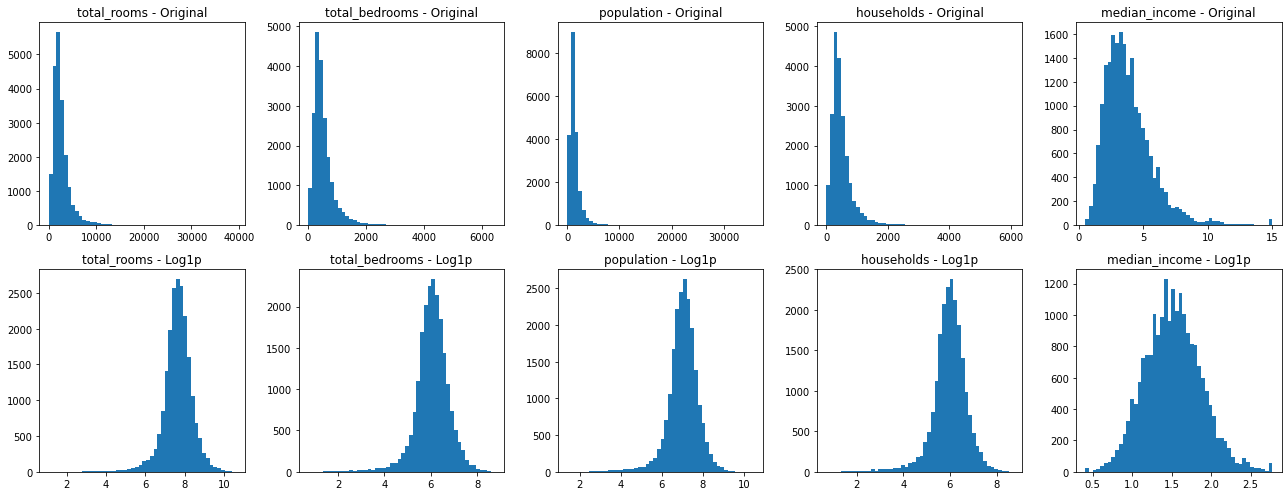

In [74]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for i, feature in enumerate(log_features):
    axes[0, i].hist(df_knn[feature], bins=50)
    axes[0, i].set_title(f"{feature} - Original")

    axes[1, i].hist(np.log1p(df_knn[feature]), bins=50)
    axes[1, i].set_title(f"{feature} - Log1p")

plt.tight_layout()
plt.show()

In [75]:
from sklearn.model_selection import train_test_split

X = df_knn.drop("median_house_value", axis=1)
y = df_knn["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (16512, 9)
X_test : (4128, 9)
y_train: (16512,)
y_test : (4128,)


In [76]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = ["ocean_proximity"]

numerical_features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape :", X_test_processed.shape)

Training shape: (16512, 13)
Testing shape : (4128, 13)


In [77]:
print("Original:")
print(X["ocean_proximity"].value_counts(normalize=True))

print("\nTraining:")
print(X_train["ocean_proximity"].value_counts(normalize=True))

print("\nTesting:")
print(X_test["ocean_proximity"].value_counts(normalize=True))

Original:
<1H OCEAN    0.44
INLAND       0.32
NEAR OCEAN   0.13
NEAR BAY     0.11
ISLAND       0.00
Name: ocean_proximity, dtype: float64

Training:
<1H OCEAN    0.44
INLAND       0.32
NEAR OCEAN   0.13
NEAR BAY     0.11
ISLAND       0.00
Name: ocean_proximity, dtype: float64

Testing:
<1H OCEAN    0.43
INLAND       0.32
NEAR OCEAN   0.14
NEAR BAY     0.11
ISLAND       0.00
Name: ocean_proximity, dtype: float64


In [78]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

knn_mae = mean_absolute_error(
    actual_bedrooms,
    knn_predictions
)

knn_rmse = np.sqrt(
    mean_squared_error(
        actual_bedrooms,
        knn_predictions
    )
)

print("KNN MAE:", knn_mae)
print("KNN RMSE:", knn_rmse)

KNN MAE: 41.75614692371296
KNN RMSE: 71.43328206380225


In [79]:
print("Original:")
print(X["ocean_proximity"].value_counts())

print("\nTraining:")
print(X_train["ocean_proximity"].value_counts())

print("\nTesting:")
print(X_test["ocean_proximity"].value_counts())

Original:
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: ocean_proximity, dtype: int64

Training:
<1H OCEAN     7341
INLAND        5227
NEAR OCEAN    2086
NEAR BAY      1854
ISLAND           4
Name: ocean_proximity, dtype: int64

Testing:
<1H OCEAN     1795
INLAND        1324
NEAR OCEAN     572
NEAR BAY       436
ISLAND           1
Name: ocean_proximity, dtype: int64


In [81]:
print(preprocessor.get_feature_names_out())

AttributeError: 'ColumnTransformer' object has no attribute 'get_feature_names_out'

In [82]:
print(preprocessor.named_transformers_["cat"].categories_)

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


In [83]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [84]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_pred = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, y_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Baseline MAE :", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE : 31609.135305232558
Baseline RMSE: 48964.763175646614


In [85]:
X_train_log = X_train.copy()
X_test_log = X_test.copy()

log_features = [
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

for feature in log_features:
    X_train_log[feature] = np.log1p(X_train_log[feature])
    X_test_log[feature] = np.log1p(X_test_log[feature])

print(X_train_log[log_features].head())

       total_rooms  total_bedrooms  population  households  median_income
14196         8.05            6.44        7.74        6.44           1.45
8267          8.13            6.67        7.18        6.63           1.57
17445         7.55            5.81        6.82        5.82           1.64
14265         7.26            5.91        7.26        5.87           1.08
2271          7.78            6.07        6.77        5.94           1.52


In [86]:
log_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

log_model.fit(X_train_log, y_train)

y_pred_log = log_model.predict(X_test_log)

log_mae = mean_absolute_error(y_test, y_pred_log)
log_rmse = np.sqrt(mean_squared_error(y_test, y_pred_log))

print("Log-transformed MAE :", log_mae)
print("Log-transformed RMSE:", log_rmse)

Log-transformed MAE : 31605.91100532946
Log-transformed RMSE: 48944.63264731133


In [87]:
error_analysis = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
})

error_analysis["Error"] = (
    error_analysis["Actual"] - error_analysis["Predicted"]
)

error_analysis["Absolute_Error"] = (
    abs(error_analysis["Error"])
)

print(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

        Actual  Predicted      Error  Absolute_Error
872  500001.00  141092.00  358909.00       358909.00
1649 500001.00  165262.99  334738.01       334738.01
1140 500001.00  192432.01  307568.99       307568.99
1250  67500.00  368456.07 -300956.07       300956.07
3693 500001.00  202391.00  297610.00       297610.00
1865 500001.00  203252.00  296749.00       296749.00
2250 500001.00  223077.02  276923.98       276923.98
285  125000.00  395872.34 -270872.34       270872.34
194  390800.00  146293.00  244507.00       244507.00
3146 500001.00  261793.01  238207.99       238207.99


In [88]:
error_analysis["Actual_Capped"] = (
    error_analysis["Actual"] == 500001
)

print(
    error_analysis["Actual_Capped"].value_counts()
)

print("\nMean absolute error:")
print(
    error_analysis.groupby("Actual_Capped")["Absolute_Error"].mean()
)

False    3949
True      179
Name: Actual_Capped, dtype: int64

Mean absolute error:
Actual_Capped
False   29694.87
True    73840.53
Name: Absolute_Error, dtype: float64


In [89]:
test_analysis = X_test.copy()
test_analysis["Actual_Value"] = y_test.values
test_analysis["Predicted_Value"] = y_pred
test_analysis["Absolute_Error"] = abs(
    y_test.values - y_pred
)

print(
    test_analysis.groupby(
        test_analysis["Actual_Value"] == 500001
    )["median_income"].describe()
)

               count  mean  std  min  25%  50%   75%   max
Actual_Value                                              
False        3949.00  3.66 1.57 0.50 2.52 3.42  4.52 13.11
True          179.00  7.69 3.47 0.50 4.76 7.45 10.36 15.00


In [90]:
test_analysis["Income_Bin"] = pd.qcut(
    test_analysis["median_income"],
    q=5,
    duplicates="drop"
)

income_error = test_analysis.groupby("Income_Bin")["Absolute_Error"].agg(
    ["count", "mean", "median"]
)

print(income_error)

                count     mean   median
Income_Bin                             
(0.499, 2.346]    826 22942.01 12515.50
(2.346, 3.12]     825 27767.51 17332.00
(3.12, 3.908]     826 31474.61 19088.50
(3.908, 5.031]    825 33725.00 22516.00
(5.031, 15.0]     826 42134.45 30318.48


In [91]:
correlations = df_knn[
    [
        "median_income",
        "housing_median_age",
        "total_rooms",
        "total_bedrooms",
        "population",
        "households",
        "median_house_value"
    ]
].corr()["median_house_value"].sort_values(ascending=False)

print(correlations)

median_house_value    1.00
median_income         0.69
total_rooms           0.13
housing_median_age    0.11
households            0.07
total_bedrooms        0.05
population           -0.02
Name: median_house_value, dtype: float64


In [92]:
rf_model = baseline_model.named_steps["model"]
encoder = baseline_model.named_steps["preprocessor"].named_transformers_["cat"]

feature_names = list(encoder.categories_[0]) + numerical_features

importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(importance_df)

               Feature  Importance
12       median_income        0.49
1               INLAND        0.14
5            longitude        0.11
6             latitude        0.10
7   housing_median_age        0.05
10          population        0.03
9       total_bedrooms        0.02
8          total_rooms        0.02
11          households        0.02
4           NEAR OCEAN        0.01
0            <1H OCEAN        0.00
3             NEAR BAY        0.00
2               ISLAND        0.00


In [93]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    baseline_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

perm_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("Importance", ascending=False)

print(perm_importance_df)

              Feature  Importance    Std
7       median_income    40201.23 875.93
0           longitude    37882.66 367.97
1            latitude    34142.20 439.08
8     ocean_proximity    20056.55 519.87
2  housing_median_age     5243.03 207.98
5          population     4923.91 147.36
3         total_rooms     2328.82  89.07
4      total_bedrooms     2178.83 152.91
6          households     1164.79  85.17


In [94]:
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

for data in [X_train_fe, X_test_fe]:
    data["rooms_per_household"] = (
        data["total_rooms"] / data["households"]
    )
    
    data["bedrooms_per_room"] = (
        data["total_bedrooms"] / data["total_rooms"]
    )
    
    data["population_per_household"] = (
        data["population"] / data["households"]
    )

print(
    X_train_fe[
        [
            "rooms_per_household",
            "bedrooms_per_room",
            "population_per_household"
        ]
    ].describe()
)

       rooms_per_household  bedrooms_per_room  population_per_household
count             16512.00           16512.00                  16512.00
mean                  5.44               0.21                      3.10
std                   2.39               0.06                     11.58
min                   0.89               0.10                      0.69
25%                   4.45               0.18                      2.43
50%                   5.24               0.20                      2.82
75%                   6.06               0.24                      3.28
max                 141.91               1.00                   1243.33


In [95]:
print("rooms_per_household > 20:",
      (X_train_fe["rooms_per_household"] > 20).sum())

print("population_per_household > 10:",
      (X_train_fe["population_per_household"] > 10).sum())

print("population_per_household > 100:",
      (X_train_fe["population_per_household"] > 100).sum())

rooms_per_household > 20: 58
population_per_household > 10: 35
population_per_household > 100: 4


In [96]:
feature_engineered_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

feature_engineered_model.fit(X_train_fe, y_train)

y_pred_fe = feature_engineered_model.predict(X_test_fe)

fe_mae = mean_absolute_error(y_test, y_pred_fe)
fe_rmse = np.sqrt(mean_squared_error(y_test, y_pred_fe))

print("Feature-engineered MAE :", fe_mae)
print("Feature-engineered RMSE:", fe_rmse)

Feature-engineered MAE : 31908.48421511628
Feature-engineered RMSE: 49825.734816156546


In [97]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_300 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_300.fit(X_train, y_train)

y_pred_300 = rf_300.predict(X_test)

mae_300 = mean_absolute_error(y_test, y_pred_300)
rmse_300 = np.sqrt(mean_squared_error(y_test, y_pred_300))

print("300-tree RF MAE :", mae_300)
print("300-tree RF RMSE:", rmse_300)

300-tree RF MAE : 31436.515616925066
300-tree RF RMSE: 48699.295159652866


In [98]:
rf_depth30 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_depth=30,
        random_state=42,
        n_jobs=-1
    ))
])

rf_depth30.fit(X_train, y_train)

y_pred_depth30 = rf_depth30.predict(X_test)

mae_depth30 = mean_absolute_error(y_test, y_pred_depth30)
rmse_depth30 = np.sqrt(mean_squared_error(y_test, y_pred_depth30))

print("Depth-30 RF MAE :", mae_depth30)
print("Depth-30 RF RMSE:", rmse_depth30)

Depth-30 RF MAE : 31436.757109528586
Depth-30 RF RMSE: 48696.11276548099


In [99]:
rf_leaf2 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_leaf2.fit(X_train, y_train)

y_pred_leaf2 = rf_leaf2.predict(X_test)

mae_leaf2 = mean_absolute_error(y_test, y_pred_leaf2)
rmse_leaf2 = np.sqrt(mean_squared_error(y_test, y_pred_leaf2))

print("Leaf-2 RF MAE :", mae_leaf2)
print("Leaf-2 RF RMSE:", rmse_leaf2)

Leaf-2 RF MAE : 31435.980199425947
Leaf-2 RF RMSE: 48775.89421811696


In [100]:
for max_features in [1.0, "sqrt", 0.7]:

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_features=max_features,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    print(
        f"max_features={max_features} | "
        f"MAE={mae:.2f} | RMSE={rmse:.2f}"
    )

max_features=1.0 | MAE=31436.52 | RMSE=48699.30
max_features=sqrt | MAE=32685.51 | RMSE=49692.50
max_features=0.7 | MAE=31245.86 | RMSE=48278.10


In [101]:
from sklearn.model_selection import cross_val_score

cv_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=300,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    ))
])

cv_scores = cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

cv_mae_scores = -cv_scores

print("CV MAE scores:", cv_mae_scores)
print("Mean CV MAE:", cv_mae_scores.mean())
print("Std CV MAE:", cv_mae_scores.std())

CV MAE scores: [31964.27068019 31813.22375416 31588.72292247 31538.3069251
 32869.65283061]
Mean CV MAE: 31954.835422505497
Std CV MAE: 482.6112577843229


In [102]:
rf_500 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=500,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    ))
])

cv_scores_500 = cross_val_score(
    rf_500,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

cv_mae_500 = -cv_scores_500

print("CV MAE scores:", cv_mae_500)
print("Mean CV MAE:", cv_mae_500.mean())
print("Std CV MAE:", cv_mae_500.std())

CV MAE scores: [31996.60073812 31774.07754102 31552.18844276 31539.71776923
 32816.62803755]
Mean CV MAE: 31935.842505737186
Std CV MAE: 471.1152441975358


In [103]:
for max_features in [0.5, 0.7, 0.9]:

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_features=max_features,
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    scores = -scores

    print(
        f"max_features={max_features} | "
        f"Mean MAE={scores.mean():.2f} | "
        f"Std={scores.std():.2f}"
    )

max_features=0.5 | Mean MAE=32155.98 | Std=445.16
max_features=0.7 | Mean MAE=31954.84 | Std=482.61
max_features=0.9 | Mean MAE=31966.99 | Std=538.21


In [104]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    ))
])

gb_scores = cross_val_score(
    gb_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

gb_mae = -gb_scores

print("CV MAE scores:", gb_mae)
print("Mean CV MAE:", gb_mae.mean())
print("Std CV MAE:", gb_mae.std())

CV MAE scores: [38700.94720847 38133.63090536 38043.35309821 38014.27822938
 38885.54964129]
Mean CV MAE: 38355.55181654176
Std CV MAE: 364.2472409884011


In [105]:
try:
    import xgboost
    print("XGBoost is installed.")
    print("Version:", xgboost.__version__)
except ImportError:
    print("XGBoost is NOT installed.")

XGBoost is installed.
Version: 1.5.2


In [106]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [107]:
from sklearn.model_selection import train_test_split

X = df_knn.drop("median_house_value", axis=1)
y = df_knn["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

X_train: (16512, 9)
X_test : (4128, 9)


In [108]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

xgb_scores = cross_val_score(
    xgb_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

xgb_mae = -xgb_scores

print("CV MAE scores:", xgb_mae)
print("Mean CV MAE:", xgb_mae.mean())
print("Std CV MAE:", xgb_mae.std())

CV MAE scores: [31675.5605995  31405.27037565 31453.9411661  32005.31449098
 32978.7905584 ]
Mean CV MAE: 31903.77543812707
Std CV MAE: 577.7383266208872


In [109]:
xgb_300 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

xgb_scores_300 = cross_val_score(
    xgb_300,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

xgb_mae_300 = -xgb_scores_300

print("CV MAE scores:", xgb_mae_300)
print("Mean CV MAE:", xgb_mae_300.mean())
print("Std CV MAE:", xgb_mae_300.std())

CV MAE scores: [31361.29413128 31063.88849744 31195.71916227 31786.54851522
 32755.30445386]
Mean CV MAE: 31632.55095201465
Std CV MAE: 611.8937714907745


In [110]:
xgb_slow = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

xgb_scores_slow = cross_val_score(
    xgb_slow,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

xgb_mae_slow = -xgb_scores_slow

print("CV MAE scores:", xgb_mae_slow)
print("Mean CV MAE:", xgb_mae_slow.mean())
print("Std CV MAE:", xgb_mae_slow.std())

CV MAE scores: [30800.69829275 30508.6649483  30099.61797419 30681.22097166
 31769.07135945]
Mean CV MAE: 30771.854709269548
Std CV MAE: 552.2062209660896


In [111]:
xgb_slower = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=800,
        learning_rate=0.03,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

xgb_scores_slower = cross_val_score(
    xgb_slower,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

xgb_mae_slower = -xgb_scores_slower

print("CV MAE scores:", xgb_mae_slower)
print("Mean CV MAE:", xgb_mae_slower.mean())
print("Std CV MAE:", xgb_mae_slower.std())

CV MAE scores: [30845.06576053 30514.83677008 30372.70394659 30729.46799762
 31772.51763964]
Mean CV MAE: 30846.918422890525
Std CV MAE: 491.05794738959526


In [112]:
xgb_depth = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

xgb_scores_depth = cross_val_score(
    xgb_depth,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

xgb_mae_depth = -xgb_scores_depth

print("CV MAE scores:", xgb_mae_depth)
print("Mean CV MAE:", xgb_mae_depth.mean())
print("Std CV MAE:", xgb_mae_depth.std())

CV MAE scores: [30181.39545607 29912.19977341 29166.21261499 30206.49610913
 31322.0791962 ]
Mean CV MAE: 30157.676629959413
Std CV MAE: 693.1145707051719


In [113]:
xgb_depth6 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

xgb_scores_depth6 = cross_val_score(
    xgb_depth6,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

xgb_mae_depth6 = -xgb_scores_depth6

print("CV MAE scores:", xgb_mae_depth6)
print("Mean CV MAE:", xgb_mae_depth6.mean())
print("Std CV MAE:", xgb_mae_depth6.std())

CV MAE scores: [30800.69829275 30508.6649483  30099.61797419 30681.22097166
 31769.07135945]
Mean CV MAE: 30771.854709269548
Std CV MAE: 552.2062209660896


In [114]:
final_xgb = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=8,
        random_state=42,
        n_jobs=-1,
        objective="reg:squarederror"
    ))
])

final_xgb.fit(X_train, y_train)

print("Final model trained.")

Final model trained.


In [115]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

y_pred_final = final_xgb.predict(X_test)

final_mae = mean_absolute_error(y_test, y_pred_final)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))

print("Final Test MAE:", final_mae)
print("Final Test RMSE:", final_rmse)

Final Test MAE: 29796.99811689983
Final Test RMSE: 45798.83597587012


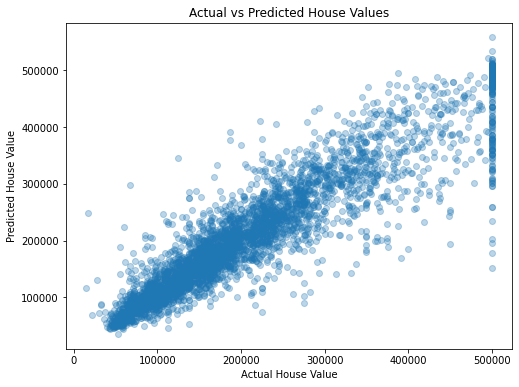

In [116]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_final, alpha=0.3)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted House Values")

plt.show()

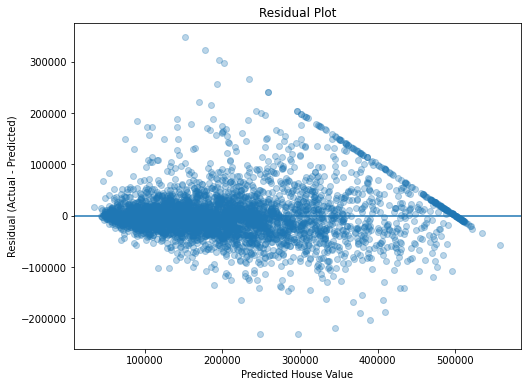

In [117]:
residuals = y_test - y_pred_final

plt.figure(figsize=(8, 6))

plt.scatter(y_pred_final, residuals, alpha=0.3)

plt.axhline(0)

plt.xlabel("Predicted House Value")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")

plt.show()

In [118]:
model = final_xgb.named_steps["model"]

importance = model.feature_importances_

feature_names = (
    ["ocean_proximity_<1H OCEAN",
     "ocean_proximity_INLAND",
     "ocean_proximity_ISLAND",
     "ocean_proximity_NEAR BAY",
     "ocean_proximity_NEAR OCEAN"]
    + numerical_features
)

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print(feature_importance_df)

                       Feature  Importance
1       ocean_proximity_INLAND        0.56
12               median_income        0.22
6                     latitude        0.04
5                    longitude        0.03
4   ocean_proximity_NEAR OCEAN        0.03
7           housing_median_age        0.03
10                  population        0.02
9               total_bedrooms        0.02
11                  households        0.01
2       ocean_proximity_ISLAND        0.01
8                  total_rooms        0.01
0    ocean_proximity_<1H OCEAN        0.01
3     ocean_proximity_NEAR BAY        0.01


In [119]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    final_xgb,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

print(perm_df)

              Feature  Importance
0           longitude    51104.49
1            latitude    47068.10
7       median_income    34093.35
8     ocean_proximity    14509.27
3         total_rooms    13411.63
5          population    12143.29
4      total_bedrooms     8112.26
2  housing_median_age     5042.31
6          households     4943.93
